In [ ]:
import os
os.chdir('/home/hedi/HSCNG/')
import pandas as pd
import h5py
# import fitsio
import numpy as np
import matplotlib.pyplot as plt

import math, time
import sys
import numpy as np
import astropy.io.fits as pyfits

import numpy as np, time, astropy.io.fits, os, sys
from hsc_y3_utils import map_utils as mu
import healpy as hp

import pymaster as nmt

In [2]:
def compute_power_spectrum_spin2(map01=None,map02=None,mask1=None,lx_rad=None,ly_rad= None,b=None):
    """
    Code to calculate the cross-power spectrum for flat sky using Namaster 
    map1 = spin-2 quantity 
    map2 = spin-2 quantity 
    b = namaster binning scheme
    output:
    cl_uncoupled = auto (cross)-power spectrum after correct the mode-coupling
    """                
 
    #Generate binning scheme
    #Generate fields
    f0 = nmt.NmtFieldFlat(lx_rad,ly_rad, mask1,[map01, map02]) #spin 2
    
    #Compute workspace if needed
    wsp=nmt.NmtWorkspaceFlat()
    wsp.compute_coupling_matrix(f0,f0,b)

    #Compute power spectrum
    cl_coupled = nmt.compute_coupled_cell_flat(f0,f0,b)
    cl_uncoupled = wsp.decouple_cell(cl_coupled)

    return cl_uncoupled #EE, EB, BE, BB 




def compute_power_spectrum_spin0_flat(map01=None,mask1=None,lx_rad=None,ly_rad= None,b=None):
    """
    Code to calculate the cross-power spectrum for flat sky using Namaster 
    map1 = spin-2 quantity 
    map2 = spin-2 quantity 
    b = namaster binning scheme
    output:
    cl_uncoupled = auto (cross)-power spectrum after correct the mode-coupling
    """                
 
    #Generate binning scheme
    #Generate fields
    f0 = nmt.NmtFieldFlat(lx_rad,ly_rad, mask1,[map01]) #spin 2
    
    #Compute workspace if needed
    wsp=nmt.NmtWorkspaceFlat()
    wsp.compute_coupling_matrix(f0,f0,b)

    #Compute power spectrum
    cl_coupled = nmt.compute_coupled_cell_flat(f0,f0,b)
    cl_uncoupled = wsp.decouple_cell(cl_coupled)

    return cl_uncoupled #EE, EB, BE, BB 



def compute_power_spectrum_spin2(map01=None,map02=None,mask1=None,lx_rad=None,ly_rad= None,b=None):
    """
    Code to calculate the cross-power spectrum for flat sky using Namaster 
    map1 = spin-2 quantity 
    map2 = spin-2 quantity 
    b = namaster binning scheme
    output:
    cl_uncoupled = auto (cross)-power spectrum after correct the mode-coupling
    """                
 
    #Generate binning scheme
    #Generate fields
    f0 = nmt.NmtFieldFlat(lx_rad,ly_rad, mask1,[map01, map02]) #spin 2
    
    #Compute workspace if needed
    wsp=nmt.NmtWorkspaceFlat()
    wsp.compute_coupling_matrix(f0,f0,b)

    #Compute power spectrum
    cl_coupled = nmt.compute_coupled_cell_flat(f0,f0,b)
    cl_uncoupled = wsp.decouple_cell(cl_coupled)

    return cl_uncoupled #EE, EB, BE, BB 



def make_shear_maps_realdata_alldata(path, fname, nfield, pixel_scale ): 
 
    """
    Generate calibrated shear maps (g1, g2) and the corresponding mask for
    real HSC-Y3 data, using all chopped fields.
    
    This function loads all chopped shape catalogs, calibrates the shear using
    the HSC-Y3 calibration scheme, constructs shear maps on a regular grid
    defined by a WCS projection, and returns the maps along with metadata
    useful for subsequent kappa reconstruction or correlation function
    measurements.
    
    Parameters
    ----------
    path : str
        Directory containing the chopped FITS shape catalogs.
    fname : str
        Base filename for the catalog set. Files are expected to follow:
        ``hscy3_shape_chopped_{fname}_{j}.fits`` for j in [0, nfield-1].
    nfield : int
        Number of chopped fields to load and aggregate.
    pixel_scale : float
        Pixel size of the output shear map in arcminutes.
    
    Returns
    -------
    mask_z : ndarray
        Transformed map mask indicating which pixels contain data.
    g1_map : ndarray
        Shear component γ₁ mapped onto the output WCS grid.
    g2_map : ndarray
        Shear component γ₂ mapped onto the output WCS grid.
    map_size : `~astropy.units.Quantity`
        Angular size of the map in degrees, as ``[ΔRA, ΔDec]``.
    e1_hat : ndarray
        Calibrated shear component 1 for each galaxy.
    e2_hat : ndarray
        Calibrated shear component 2 for each galaxy.
    weights_cat : ndarray
        Shape weights for each galaxy (carried through from the catalog).
    flat_obj : FlatClass
        Mapping/geometry object used to interpolate between sky and grid.
    ra_cat : ndarray
        Source right ascension positions (degrees).
    dec_cat : ndarray
        Source declination positions (degrees).
    nmap : ndarray
        Number of objects per pixel (before transformation).

    """
    
    import astropy.units as u
    e1_cat,e2_cat, ra_cat,dec_cat, obj_id_cat, sigmae_cat, erms_cat, weights_cat, m_cat, c1_cat,c2_cat, res_cat, flux_cat, zbin_cat, bmask_cat, psf11_cat, psf22_cat,psf12_cat, epsf1_cat, epsf2_cat =  mu.read_real_data_allchopped(path ,fname, nfield)
    # pixel_scale= 0.5
    wcs, shape = mu.set_wcs_shape(ra_cat, dec_cat, pixel_scale, pad= 1.0)
    flat_obj = mu.FlatClass(wcs, nx= shape[0], ny= shape[1])
    map_size = [(np.max(ra_cat) - np.min(ra_cat)), (np.max(dec_cat) - np.min(dec_cat))]*u.degree
    
    
    # # When working on real catalogs, we need some calibrations to get an unbiased shear as below
    #  #calibrate shear
    e1_hat, e2_hat =  mu.calib_shear_y3(weights_cat, m_cat, erms_cat, e1_cat, e2_cat, c1_cat, c2_cat, flux_cat, res_cat, epsf1_cat, epsf2_cat)
    
    # # #make the gamma-maps:
    [g1_map, g2_map], [mask, nmap] = mu.create_shear_map(ra_cat,dec_cat,e1_hat, e2_hat, flat_obj, weights= weights_cat)
    
    mask_z = flat_obj.transform_mapsize(mask)
    g1_map = flat_obj.transform_mapsize(g1_map)
    g2_map = flat_obj.transform_mapsize(g2_map)
    ndens_map = flat_obj.transform_mapsize(nmap)

    return mask_z, g1_map, g2_map, map_size, e1_hat, e2_hat, weights_cat,flat_obj, ra_cat, dec_cat, ndens_map



def convert_to_pix_coord(ra, dec, nside=1024):
    """
    Converts RA,DEC to hpix coordinates
    """

    theta = (90.0 - dec) * np.pi / 180.
    phi = ra * np.pi / 180.
    pix = hp.ang2pix(nside, theta, phi, nest=False)

    return pix



def healpix_KS_map(gmap, lmax=None, sigma=None):
    """
    Compute convergence (kappa) E/B maps from a Healpix shear map.

    This implements the spherical Kaiser–Squires inversion using
    spin-2 spherical harmonics.

    Parameters
    ----------
    gmap: ndarray
        Healpix convergence map (ring format)
    lmax: int
        Maximum multipole order
    sigma: float
        Gaussian smoothing applied to the alms [arcmin]
    """
    nside = hp.npix2nside(gmap.shape[1])

    if sigma is not None:
        # convert to radians
        sigma = sigma / 60./180*np.pi

    if lmax is None:
        lmax = 2*nside

    KQU_maps = [np.zeros_like(gmap[0]), gmap[0], gmap[1]]
    alms = hp.map2alm(KQU_maps, lmax=lmax, pol=True)

    ell, emm = hp.Alm.getlm(lmax=lmax)
    almsE = alms[1]*((ell*(ell+1.))/((ell+2.)*(ell-1)))**0.5
    almsB = alms[2]*((ell*(ell+1.))/((ell+2.)*(ell-1)))**0.5
    almsE[ell==0] = 0.0
    almsB[ell==0] = 0.0
    almsE[ell==1] = 0.0
    almsB[ell==1] = 0.0

    E_map = hp.alm2map(almsE, nside=nside, lmax=lmax, pol=False, sigma=sigma, verbose=False)
    B_map = hp.alm2map(almsB, nside=nside, lmax=lmax, pol=False, sigma=sigma, verbose=False)
    return E_map, B_map


def make_maps_curved_shear_maps(e1_hat, e2_hat, weights_cat, ra_cat, dec_cat , nside,sigma=None): 
 
    """
   
    Build curved-sky (Healpix) and flat-sky (gnomonic) shear and convergence maps.

    This function performs:
        1. Catalog → Healpix binning
        2. Kaiser–Squires inversion (spherical harmonics)
        3. Gnomonic projection (flat-sky)

    Parameters
    ----------
    e1_hat, e2_hat : ndarray
        Calibrated shear components.
    weights_cat : ndarray
        Galaxy weights.
    ra_cat, dec_cat : ndarray
        Sky coordinates in degrees.
    nside : int
        Healpix resolution parameter.
    sigma : float, optional
        Gaussian smoothing scale in arcmin (applied in harmonic space).

    Returns
    -------
 
   Curved-sky maps: gamma1, gamma2, mask , E_map, B_map
   Flat-sky maps, E, B, mask
   map-size and resolution of the map

    Notes
    -----
    - Assumes Healpix RING ordering.
    - Uses polarization formalism for spin-2 transform.
    - No mask deconvolution (pseudo-Cl effects remain).
    """
    # -------------------------
    # 1. Catalog → Healpix binning
    # -------------------------
    npix = hp.nside2npix(nside)
    pix1 = convert_to_pix_coord(ra_cat,dec_cat, nside=nside)
    unique_pix1, idx1, idx_rep1 = np.unique(pix1, return_index=True, return_inverse=True)
    
    w_sum = np.zeros(npix)
    e1_w = np.zeros(npix)
    e2_w = np.zeros(npix)
    
    np.add.at(w_sum, pix1, weights_cat)
    np.add.at(e1_w, pix1, e1_hat * weights_cat)
    np.add.at(e2_w, pix1, e2_hat * weights_cat)
    
    mask = w_sum > 0
    
    e1_map = np.zeros(npix)
    e2_map = np.zeros(npix)
    
    e1_map[mask] = e1_w[mask] / w_sum[mask]
    e2_map[mask] = e2_w[mask] / w_sum[mask]
    
    # -------------------------
    # 2. Kaiser–Squires (spherical)
    # -------------------------
    E_map, B_map = healpix_KS_map(np.array([e1_map,e2_map]), sigma= sigma)
    
    # -------------------------
    # 3. Define flat-sky patch
    # -------------------------
    
    ####### free parameters to define the patch to cut out (next 3 lines)
    ra0, dec0 = np.mean(ra_cat), np.mean(dec_cat) ## center of the patch, unit: degrees; ra, dec both go from [0, 90] deg
    
    res_arcmin = hp.nside2resol(nside, arcmin=True) # map resolution in arcmin/pix
    map_size = max(
        np.max(ra_cat) - np.min(ra_cat),
        np.max(dec_cat) - np.min(dec_cat)
    )
    
    Npix = int(map_size * 60 / res_arcmin)
    # -------------------------
    # 4. Gnomonic projections
    # -------------------------
    
     
    mask_flat = hp.gnomview(mask , rot=[ra0, dec0], unit="kappa", format="%.2g",
                           title="GnomView (RA_center=%s, DEC_center=%s)" %(ra0, dec0), 
                           xsize=Npix, ## number of pixels 
                           reso=res_arcmin, ## resolution in arcmin   
                           return_projected_map=True)
    
    
    
     
    e1_flat = hp.gnomview(e1_map , rot=[ra0, dec0], unit="kappa", format="%.2g",
                           title="GnomView (RA_center=%s, DEC_center=%s)" %(ra0, dec0), 
                           xsize=Npix, ## number of pixels 
                           reso=res_arcmin, ## resolution in arcmin
                           # norm="hist",
                           return_projected_map=True)
    
    
     
    e2_flat = hp.gnomview(e2_map , rot=[ra0, dec0], unit="kappa", format="%.2g",
                           title="GnomView (RA_center=%s, DEC_center=%s)" %(ra0, dec0), 
                           xsize=Npix, ## number of pixels 
                           reso=res_arcmin, ## resolution in arcmin
                           # norm="hist",
                           return_projected_map=True)
    
    E_flat = hp.gnomview(E_map , rot=[ra0, dec0], unit="kappa", format="%.2g",
                           title="GnomView (RA_center=%s, DEC_center=%s)" %(ra0, dec0), 
                           xsize=Npix, ## number of pixels 
                           reso=res_arcmin, ## resolution in arcmin
                           # norm="hist",
                           return_projected_map=True)
    
    
    B_flat = hp.gnomview(B_map , rot=[ra0, dec0], unit="kappa", format="%.2g",
                           title="GnomView (RA_center=%s, DEC_center=%s)" %(ra0, dec0), 
                           xsize=Npix, ## number of pixels 
                           reso=res_arcmin, ## resolution in arcmin
                           # norm="hist",
                           return_projected_map=True)
    
    return e1_map, e2_map, mask ,E_map, B_map, E_flat, B_flat, mask_flat, map_size,res_arcmin

In [7]:
path_real = '/home/hedi/HSCNG/data/real/'
pixel_size = 0.5 #arcmin
name_fields = ['XMM', 'VVDS','GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches= [8, 25,23,7,26,13] # of each corresponding field
theta_g = 3 #armin #Size of the smoothing scale

In [ ]:
mask_data, g1_data, g2_data, mapsize_data, e1_hat_data, e2_hat_data,  weights_data,flat_obj_data,ra_cat, dec_cat, nmap  = make_shear_maps_realdata_alldata(path_real,'XMM',8,pixel_size )
# same procedure here

#Important to compute the power spectrum:
lx_rad = mapsize_data.decompose().value[0]
ly_rad = mapsize_data.decompose().value[1]

nbins = 20 #number of bins to compute peaks, mfs, pdf and minima
l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
ells_uncoupled = binner.get_effective_ells()


In [9]:
hp.nside2resol(2048, arcmin=True), 'resolution in arcmin of the pixels'

(np.float64(1.717743205908703), 'resolution in arcmin of the pixels')

/var/tmp/pbs.570629.idark/ipykernel_81912/3216174704.py:197: RuntimeWarning: divide by zero encountered in divide
  almsE = alms[1]*((ell*(ell+1.))/((ell+2.)*(ell-1)))**0.5
/var/tmp/pbs.570629.idark/ipykernel_81912/3216174704.py:197: RuntimeWarning: invalid value encountered in multiply
  almsE = alms[1]*((ell*(ell+1.))/((ell+2.)*(ell-1)))**0.5
/var/tmp/pbs.570629.idark/ipykernel_81912/3216174704.py:198: RuntimeWarning: divide by zero encountered in divide
  almsB = alms[2]*((ell*(ell+1.))/((ell+2.)*(ell-1)))**0.5
/var/tmp/pbs.570629.idark/ipykernel_81912/3216174704.py:198: RuntimeWarning: invalid value encountered in multiply
  almsB = alms[2]*((ell*(ell+1.))/((ell+2.)*(ell-1)))**0.5
/var/tmp/pbs.570629.idark/ipykernel_81912/3216174704.py:204: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  E_map = hp.alm2map(almsE, nside=nside, lmax=lmax, pol=False, sigma=sigma, verbose=False)
/var/tmp/pbs.570629.idark/ipykernel_81912/3

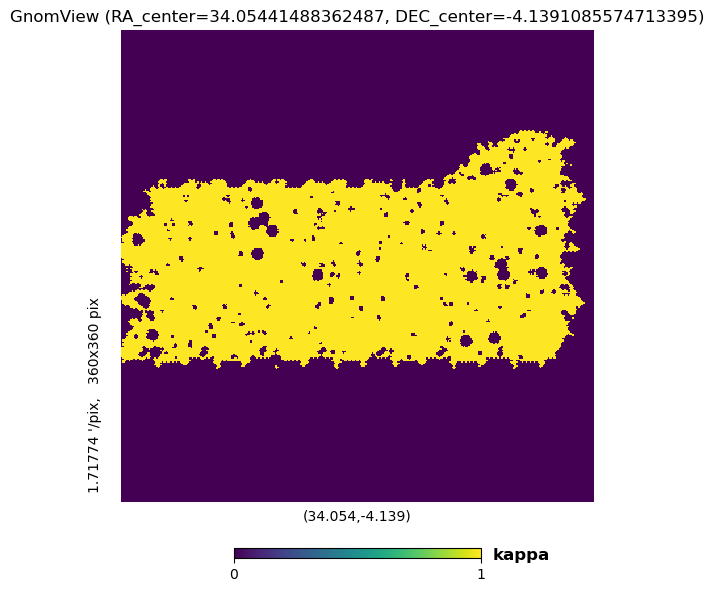

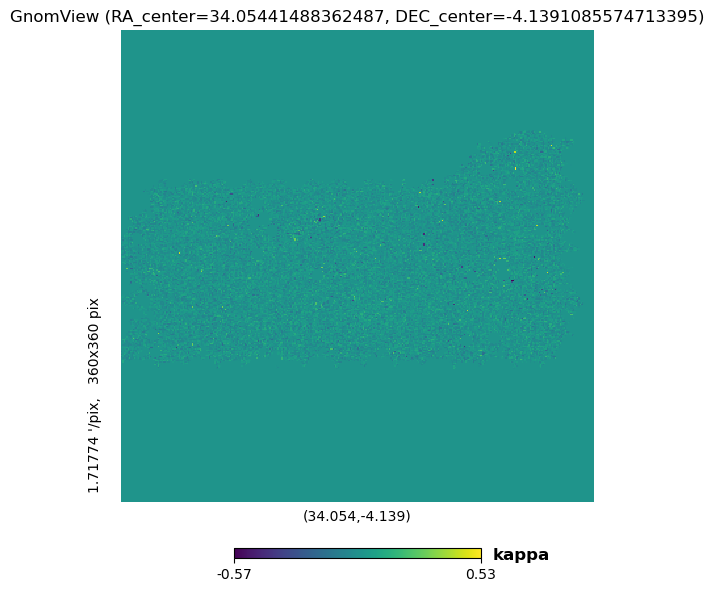

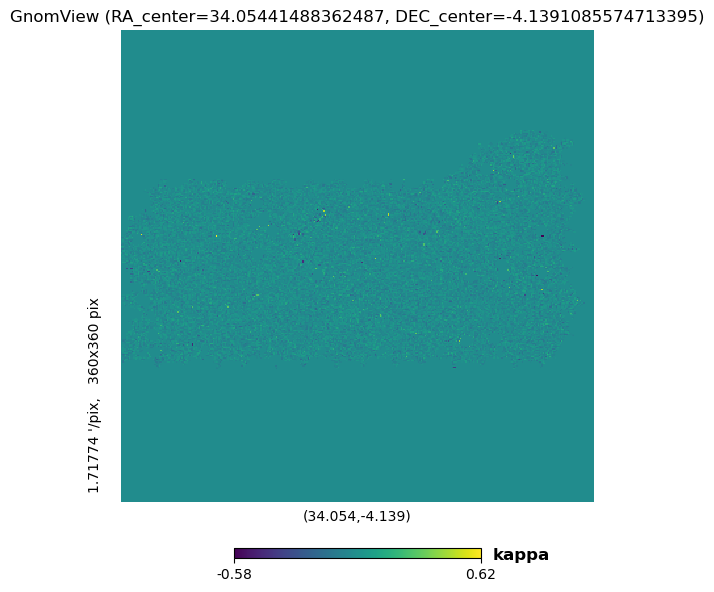

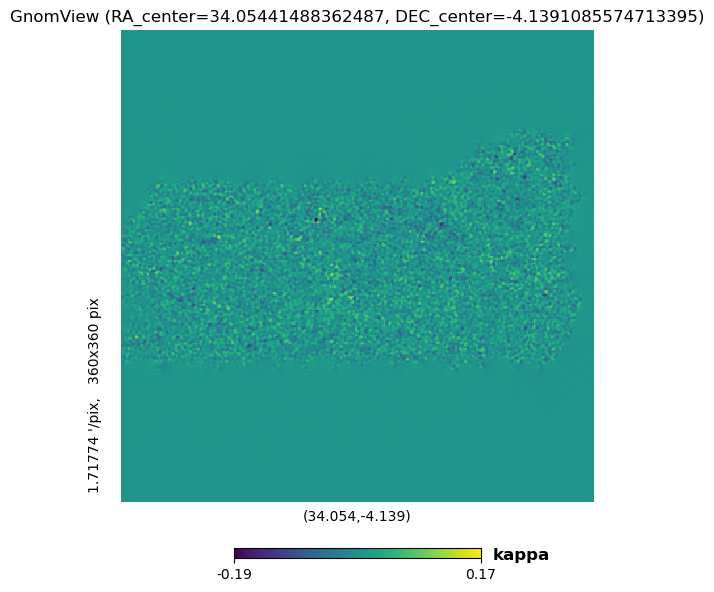

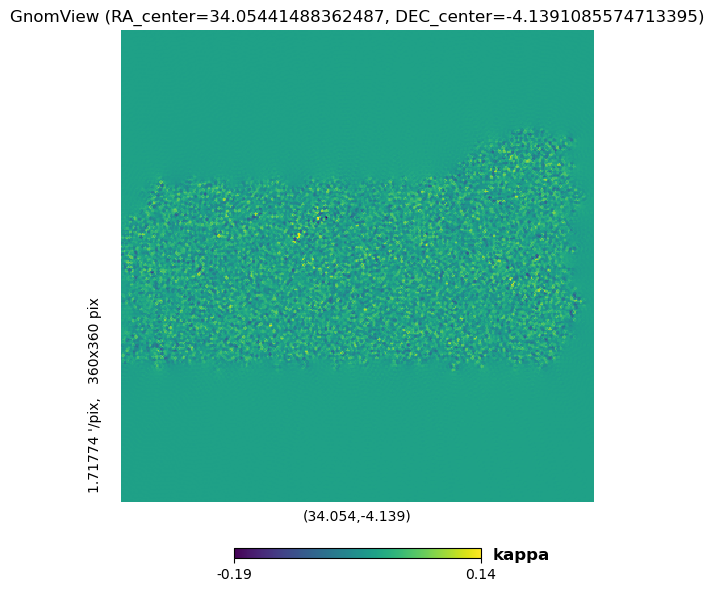

In [10]:
nside = 2048
e1_map_curved, e2_map_curved, mask_curved , E_curved, B_curved, E_flat, B_flat, mask_flat,map_size,res_arcmin = make_maps_curved_shear_maps(e1_hat_data, e2_hat_data, weights_data, ra_cat, dec_cat , nside, None)

Text(0.5, 1.0, 'flat-sky E map')

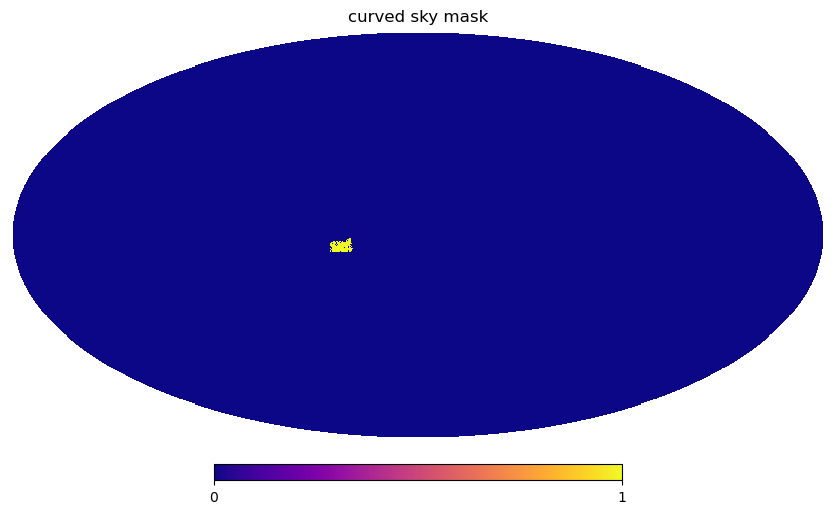

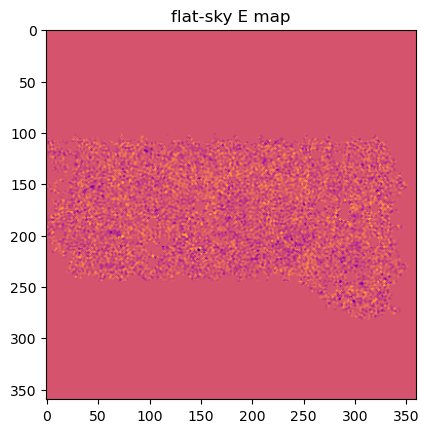

In [7]:
hp.mollview(mask_curved, title='curved sky mask',cmap='plasma')

plt.figure()
plt.imshow(E_flat*mask_flat,cmap='plasma')
plt.title('flat-sky E map')


In [8]:
cls_all_hpx = hp.anafast(np.array([np.zeros_like(e1_map_curved), e1_map_curved,e2_map_curved]), lmax= 3000) #(TT, EE, BB, TE, EB, TB for polarized input map) 

(0.0, 1024.0)

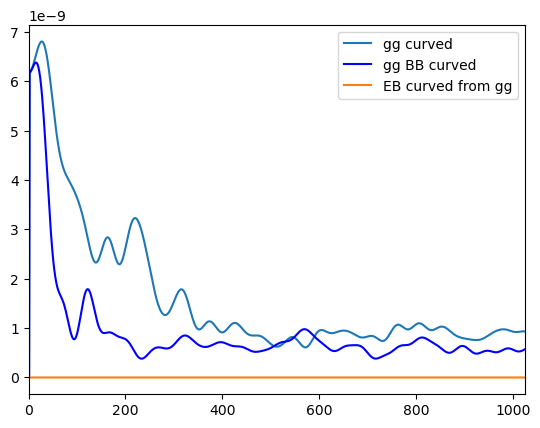

In [9]:

plt.plot(cls_all_hpx[1]/np.mean(mask_curved), label='gg curved')
plt.plot(cls_all_hpx[2]/np.mean(mask_curved),color='b', label='gg BB curved ')
plt.plot(cls_all_hpx[3]/np.mean(mask_curved), label='EB curved from gg')
plt.legend()
plt.xlim(0,1024)

## Run namaster flat for kappa:

In [10]:

#Important to compute the power spectrum:
lx_rad = max(mapsize_data.decompose().value)
ly_rad = max(mapsize_data.decompose().value)
 
nbins = 20 #number of bins to compute peaks, mfs, pdf and minima
l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
ells_uncoupled = binner.get_effective_ells()

In [11]:
cl_spin0_flat = compute_power_spectrum_spin0_flat(map01=E_flat*mask_flat,mask1=mask_flat,lx_rad=lx_rad,ly_rad= ly_rad,b=binner )
cl_BB_spin0_flat = compute_power_spectrum_spin0_flat(map01=B_flat*mask_flat,mask1=mask_flat,lx_rad=lx_rad,ly_rad= ly_rad,b=binner )


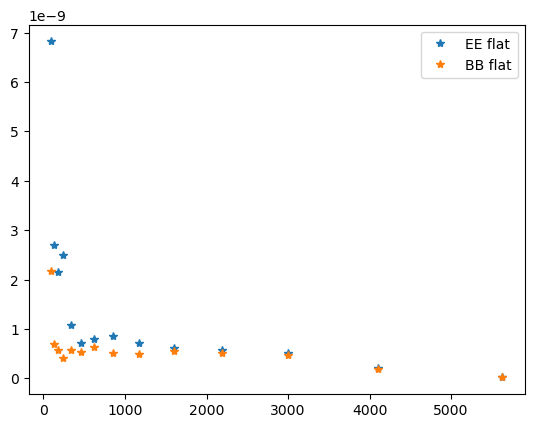

In [12]:
plt.plot(ells_uncoupled ,cl_spin0_flat[0],'*', label='EE flat')
plt.plot(ells_uncoupled ,cl_BB_spin0_flat[0],'*', label='BB flat')

plt.legend()

(0.0, 2000.0)

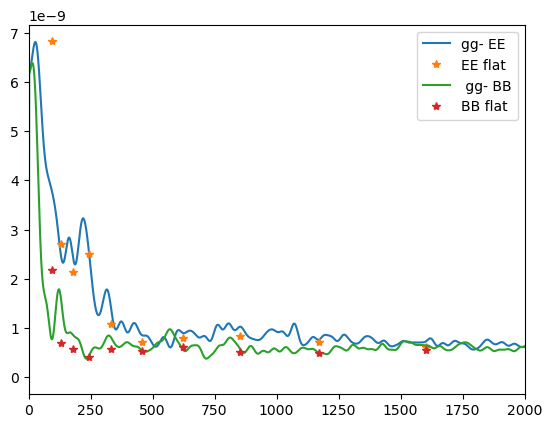

In [14]:

plt.plot(cls_all_hpx[1]/np.mean(mask_curved), label='gg- EE')

plt.plot(ells_uncoupled ,cl_spin0_flat[0],'*', label='EE flat')

plt.plot(cls_all_hpx[2]/np.mean(mask_curved), label=' gg- BB')
plt.plot(ells_uncoupled ,cl_BB_spin0_flat[0],'*', label='BB flat')

 
# plt.plot(cls_all_hpx[3]/np.mean(mask_curved), label='EB')
plt.legend()
 
plt.xlim(0,2000)